# 01 - Exploration du dataset Bike Sharing

Avant d'entraîner un perceptron multicouche (MLP), on regarde les données.

Le fichier `data/day.csv` contient **731 jours** (2011-2012) de location de vélos en libre-service.
Le but des notebooks suivants est de **prédire `cnt`**, le nombre total de locations dans la journée,
à partir de la météo et du calendrier : c'est un problème de **régression**.

| Variable | Description |
|---|---|
| `season` | 1 : hiver, 2 : printemps, 3 : été, 4 : automne |
| `yr` | 0 : 2011, 1 : 2012 |
| `mnth`, `weekday` | mois (1-12), jour de la semaine (0 = dimanche) |
| `holiday`, `workingday` | jour férié, jour ouvré (binaires) |
| `weathersit` | 1 : clair, 2 : brume/nuageux, 3 : pluie ou neige légère, 4 : forte pluie |
| `temp`, `atemp` | température et température ressentie normalisées |
| `hum`, `windspeed` | humidité et vitesse du vent normalisées |
| `casual`, `registered` | locations par des utilisateurs occasionnels / abonnés |
| `cnt` | **cible** : nombre total de locations |

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from velo_utils import load_raw, PALETTE

df = load_raw()
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


: 

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[us]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[us](1), float64(4), int

In [3]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
instant,731.0,366.0,1.0,183.5,366.0,548.5,731.0,211.165812
dteday,731,2012-01-01 00:00:00,2011-01-01 00:00:00,2011-07-02 12:00:00,2012-01-01 00:00:00,2012-07-01 12:00:00,2012-12-31 00:00:00,NaN
season,731.0,2.49658,1.0,2.0,3.0,3.0,4.0,1.110807
yr,731.0,0.500684,0.0,0.0,1.0,1.0,1.0,0.500342
mnth,731.0,6.519836,1.0,4.0,7.0,10.0,12.0,3.451913
holiday,731.0,0.028728,0.0,0.0,0.0,0.0,1.0,0.167155
weekday,731.0,2.997264,0.0,1.0,3.0,5.0,6.0,2.004787
workingday,731.0,0.683995,0.0,0.0,1.0,1.0,1.0,0.465233
weathersit,731.0,1.395349,1.0,1.0,1.0,2.0,3.0,0.544894
temp,731.0,0.495385,0.05913,0.337083,0.498333,0.655417,0.861667,0.183051


In [4]:
print("Valeurs manquantes :", df.isna().sum().sum())

Valeurs manquantes : 0


## Attention à la fuite de données

`casual + registered = cnt` pour chaque jour. Si on gardait ces deux colonnes comme variables d'entrée,
le modèle n'aurait qu'à les additionner : il aurait l'air parfait mais serait inutilisable en pratique
(on ne connaît pas ces nombres avant la fin de la journée). On les **retire** des entrées, tout comme
`instant` (simple index) et `dteday` (la date, déjà décrite par `yr`, `mnth`, `weekday`).

In [5]:
(df["casual"] + df["registered"] == df["cnt"]).all()

np.True_

## Évolution dans le temps

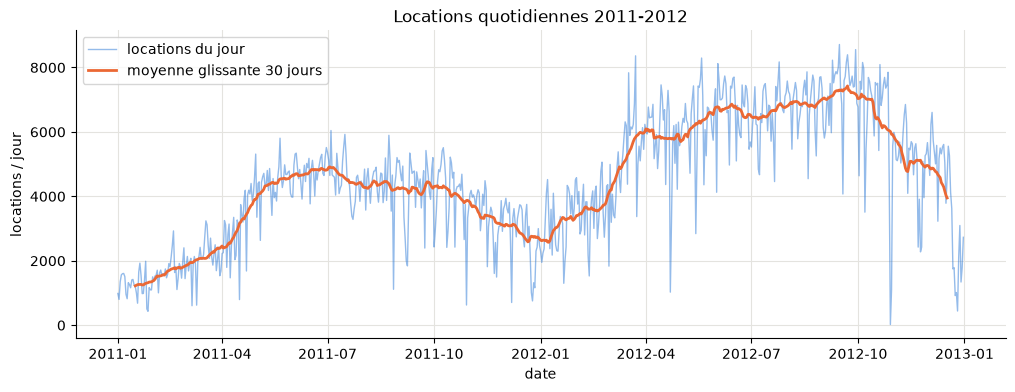

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df["dteday"], df["cnt"], lw=1, alpha=0.5, label="locations du jour")
ax.plot(df["dteday"], df["cnt"].rolling(30, center=True).mean(), label="moyenne glissante 30 jours")
ax.set(xlabel="date", ylabel="locations / jour", title="Locations quotidiennes 2011-2012")
ax.legend()
plt.show()

On voit une forte **saisonnalité** (plus de locations l'été) et une **tendance** à la hausse entre 2011 et 2012 :
la variable `yr` sera utile.

## Relation avec les variables météo

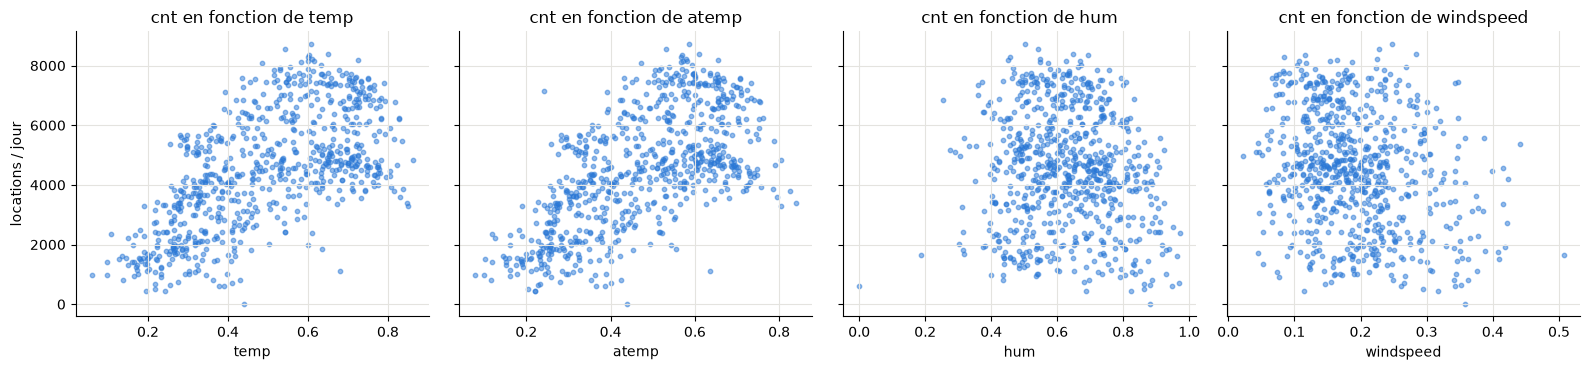

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, col in zip(axes, ["temp", "atemp", "hum", "windspeed"]):
    ax.scatter(df[col], df["cnt"], s=10, alpha=0.5, color=PALETTE[0])
    ax.set(xlabel=col, title=f"cnt en fonction de {col}")
axes[0].set_ylabel("locations / jour")
plt.tight_layout()
plt.show()

## Relation avec les variables catégorielles

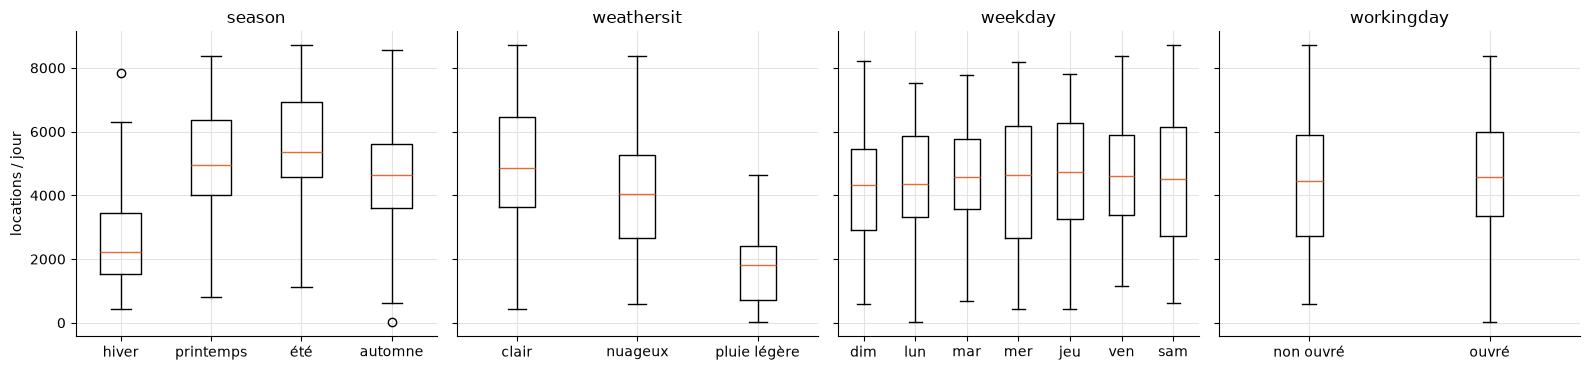

In [8]:
labels = {
    "season": {1: "hiver", 2: "printemps", 3: "été", 4: "automne"},
    "weathersit": {1: "clair", 2: "nuageux", 3: "pluie légère", 4: "forte pluie"},
    "weekday": {0: "dim", 1: "lun", 2: "mar", 3: "mer", 4: "jeu", 5: "ven", 6: "sam"},
    "workingday": {0: "non ouvré", 1: "ouvré"},
}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, (col, names) in zip(axes, labels.items()):
    groups = sorted(df[col].unique())
    ax.boxplot([df.loc[df[col] == g, "cnt"] for g in groups])
    ax.set_xticks(range(1, len(groups) + 1), [names[g] for g in groups])
    ax.set_title(col)
axes[0].set_ylabel("locations / jour")
plt.tight_layout()
plt.show()

## Corrélations

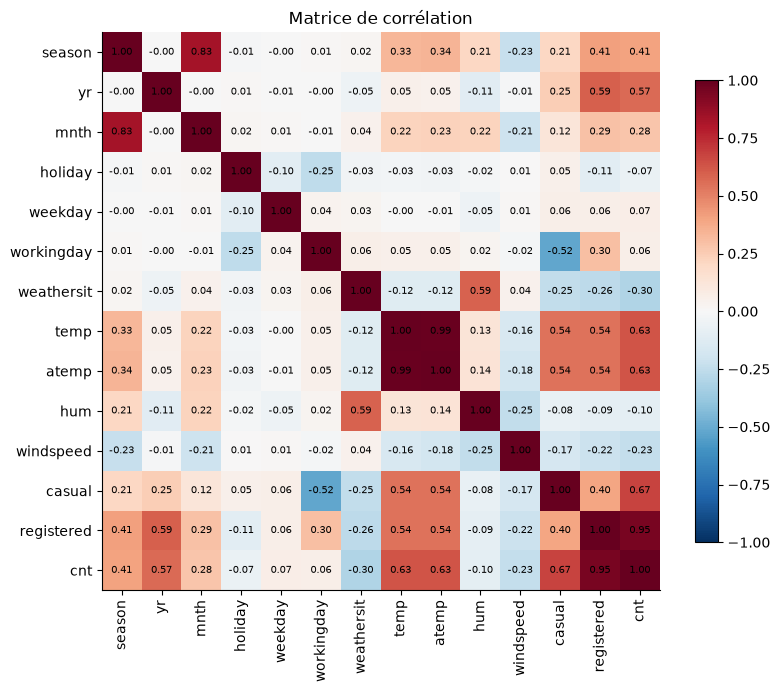

In [9]:
corr = df.drop(columns=["instant", "dteday"]).corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Matrice de corrélation")
plt.show()

In [10]:
corr["cnt"].drop(["cnt", "casual", "registered"]).sort_values(ascending=False)

atemp         0.631066
temp          0.627494
yr            0.566710
season        0.406100
mnth          0.279977
weekday       0.067443
workingday    0.061156
holiday      -0.068348
hum          -0.100659
windspeed    -0.234545
weathersit   -0.297391
Name: cnt, dtype: float64

## Ce qu'on retient pour la suite

- `temp` / `atemp` (corrélées à 0.99 entre elles) et `yr` sont les variables les plus liées à `cnt`.
- `season`, `mnth`, `weekday` et `weathersit` sont **catégorielles** : leur valeur numérique n'a pas de sens d'ordre
  (le mois 12 n'est pas « 12 fois » le mois 1). On les encode en **one-hot** (`pd.get_dummies`).
- `cnt` va jusqu'à ~8 700. Pour que le réseau converge vite, on exprime la cible **en milliers de locations**.

Tout cela est fait par la fonction `prepare()` de `velo_utils.py` :

In [11]:
from velo_utils import prepare

data = prepare()
print(data.shape)
data.head()

(731, 34)


,yr,holiday,workingday,temp,atemp,hum,windspeed,cnt,season_1,season_2,...,weekday_0,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6,weathersit_1,weathersit_2,weathersit_3
0,0.0,0.0,0.0,0.344167,0.363625,0.805833,0.160446,0.985,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1,0.0,0.0,0.0,0.363478,0.353739,0.696087,0.248539,0.801,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,1.0,0.196364,0.189405,0.437273,0.248309,1.349,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,1.0,0.200000,0.212122,0.590435,0.160296,1.562,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.0,0.0,1.0,0.226957,0.229270,0.436957,0.186900,1.600,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
